# Cross-check – the price cut, from the joining and cancellation models

**Question.** Part 1 measured the price cut against Panem with a difference-in-differences. This check asks the same question without Panem: using the Part 3 and Part 4 models, what would the five cut regions have looked like in the three post-cut seasons if the base price had stayed at \$15?

**Findings**

* **The models reproduce what happened.** Simulated at the real \$12 base, member share is within 0.4 pp of actual in every season and revenue per customer within \$0.03.
* **Membership: the two methods agree.** The cut raised member share by 10.4 pp on average, against 11.5 pp in Part 1 (95% CI 8.5 to 14.5).
* **Revenue in dollars: they agree.** +\$0.43 per customer per season, against +\$0.365 in Part 1 (CI 0.07 to 0.66).
* **Revenue in percentage terms: the model finds a gain where Part 1 could not detect one.** +0.165 log points (about +18%), against +0.015 in Part 1. It is inside Part 1's wide interval (−0.16 to +0.19). The gain is not in every season: revenue is 3% lower in spring 2019 and 25–35% higher in summer and fall.
* **Without the cut, member share would have fallen**, from 22.9% in winter 2019 to 16.0% by summer. Panem's share fell over the same seasons with no price change, so that drop was not specific to Panem.

---

## Method

* **Two scenarios, same customers.** Every customer in the five cut regions is rolled from winter 2019 through the three post-cut seasons, once with the real \$12 base and once with a \$15 base. Each person keeps their own discount depth, so every counterfactual price is \$3 higher and lies between \$10 and \$15, all charged before the cut.
* **Each season,** a prospect joins with the Part 3 probability and a member cancels with the Part 4 probability. Tenure and last season's price are then updated and carried into the next season.
* **Saved coefficients, no refitting.** Neither model has season effects, so the coefficients are all that is needed.
* **Actual ad exposure is used.** This looks back at seasons that have happened, and exposure does not depend on price or on membership (Part 3).
* **The same random draws are used in both scenarios,** so the difference between them comes only from price. With about 358,000 customers, a different seed moves the results by less than 0.03 pp.
* **One assumption.** A customer's simulated status can differ from their real one, and then the data has no price for them. A member with no recorded discount gets a depth drawn evenly from \$1–\$5; a prospect with no recorded offer status gets an offer at that season's rate among prospects.

In [14]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

import utils as u

u.apply_style()
CUT = u.CUT_T                                        # spring 2019
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#8a8a8a'
POST = [CUT, CUT + 1, CUT + 2]

panel = u.load_panel('data/customer_panel.csv',
                     extra_cols=('customer_id', 'discount_flag', 'social_ad_impressions', 'podcast_ad_listen'))
join_params = pd.read_csv('outputs/join_model_params.csv', index_col=0)['coefficient']        # Part 3
cancel_params = pd.read_csv('outputs/cancel_model_params.csv', index_col=0)['coefficient']    # Part 4


def predict(params, x):
    """Probability from saved logit coefficients. Handles plain columns and C(column)[T.level] dummies."""
    xb = np.full(len(x), params['Intercept'])
    for name, beta in params.drop('Intercept').items():
        dummy = re.fullmatch(r'C\((\w+)\)\[T\.(.+)\]', name)
        xb += beta * (x[dummy.group(1)].astype(str).eq(dummy.group(2)) if dummy else x[name]).to_numpy(float)
    return expit(xb)

In [15]:
df = (panel[panel['region_name'].ne(u.CONTROL)].sort_values(['customer_id', 't'])
       .rename(columns={'podcast_ad_listen': 'pod', 'social_ad_impressions': 'soc'}).reset_index(drop=True))
by_cust = df.groupby('customer_id')
df['prev_member'] = by_cust['sign_up_flag'].shift(1)
df['pod_last'], df['soc_last'] = by_cust['pod'].shift(1), by_cust['soc'].shift(1)
spell = (df['sign_up_flag'].eq(1) & df['prev_member'].fillna(0).eq(0)).groupby(df['customer_id']).cumsum()
df['tenure'] = np.where(df['sign_up_flag'].eq(1), df.groupby(['customer_id', spell]).cumcount() + 1, 0)


def levels(x):
    """Member share (%) and revenue per customer ($) by season."""
    out = (x.assign(paid=x['membership_price'] * x['sign_up_flag'])
            .groupby('t').agg(member_pct=('sign_up_flag', 'mean'), revenue_pc=('paid', 'mean')))
    out['member_pct'] *= 100
    return out


cut_levels, panem_levels = levels(df), levels(panel[panel['region_name'].eq(u.CONTROL)])    # actual, all seasons
did_cells = u.build_cells(panel)                         # region-season cells for Part 1's event study (chart below)
del panel

# One frame per season, every frame in the same customer order
season = {k: df[df['t'].eq(k)].set_index('customer_id').sort_index() for k in [CUT - 1, *POST]}
start = season[CUT - 1]                                  # winter 2019: where both scenarios begin
assert all(season[k].index.equals(start.index) for k in POST)
n = len(start)

# Each customer's discount depth and offer status in each post-cut season, shared by both scenarios.
# Where the data has it, use it. Where it does not (the customer's simulated status can differ from their
# real one), draw it: depth evenly from $1-$5, offer at that season's offer rate among prospects.
rng = np.random.default_rng(0)
depth, offered, draw = {}, {}, {}
for k in POST:
    s = season[k]
    has_discount = s['discount_flag'].eq(1)
    depth[k] = np.where(has_discount, 12 - s['membership_price'], rng.integers(1, 6, n))
    was_prospect = s['prev_member'].eq(0)
    offer_rate = s.loc[was_prospect, 'discount_flag'].mean()
    offered[k] = np.where(was_prospect, s['discount_flag'], rng.random(n) < offer_rate).astype(int)
    draw[k] = rng.random(n)                              # one draw per customer-season decides join / cancel

print(f"{n:,} customers in the five cut regions; {start['sign_up_flag'].mean():.1%} are members in {u.period_label(CUT - 1)}")

357,686 customers in the five cut regions; 22.9% are members in Win 2019


In [16]:
def simulate(base_price):
    """Roll the cut regions through the three post-cut seasons with the given base price."""
    member = start['sign_up_flag'].to_numpy().astype(bool)
    tenure = start['tenure'].to_numpy().copy()
    last_price = start['membership_price'].to_numpy(float).copy()
    rows = []
    for k in POST:
        s = season[k]
        member_price = base_price - depth[k]                         # members always get $1-$5 off
        prospect_price = base_price - depth[k] * offered[k]          # prospects only if offered

        x = pd.DataFrame({'region_name': s['region_name'].to_numpy(), 'pod': s['pod'].to_numpy(),
                          'soc': s['soc'].to_numpy(), 'pod_last': s['pod_last'].to_numpy(),
                          'soc_last': s['soc_last'].to_numpy()})
        p_join = predict(join_params, u.add_terms_join(x.assign(price=prospect_price, offer=offered[k])))
        p_cancel = predict(cancel_params, u.add_terms_cancel(x.assign(price=member_price, price_lag=last_price,
                                                                      tenure_group=np.clip(tenure, 1, 8))))

        stays, joins = member & (draw[k] >= p_cancel), ~member & (draw[k] < p_join)
        paid = np.where(member, member_price, prospect_price)
        rows.append({'t': k, 'member_pct': 100 * (stays | joins).mean(), 'revenue_pc': paid[stays | joins].sum() / n,
                     'joined': joins.sum(), 'cancelled': (member & ~stays).sum()})
        tenure = np.where(stays, tenure + 1, np.where(joins, 1, 0))
        last_price = np.where(stays | joins, paid, last_price)
        member = stays | joins
    return pd.DataFrame(rows).set_index('t')


actual = pd.DataFrame({k: {'member_pct': 100 * season[k]['sign_up_flag'].mean(),
                           'revenue_pc': (season[k]['membership_price'] * season[k]['sign_up_flag']).sum() / n,
                           'joined': (season[k]['prev_member'].eq(0) & season[k]['sign_up_flag'].eq(1)).sum(),
                           'cancelled': (season[k]['prev_member'].eq(1) & season[k]['sign_up_flag'].eq(0)).sum()}
                       for k in POST}).T.rename_axis('t')
with_cut, no_cut = simulate(12), simulate(15)

runs = pd.concat({'actual': actual, 'simulated, $12 base': with_cut, 'simulated, $15 base (no cut)': no_cut}, axis=1)
runs.index = runs.index.map(u.period_label)
runs.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False).round(2)

cancelled                                                    joined  \
             actual simulated, $12 base simulated, $15 base (no cut)   actual   
t                                                                               
Spr 2019     6802.0                7589                        16435  12201.0   
Sum 2019     7981.0                8418                        16597  21787.0   
Fall 2019    7245.0                6821                         8492  34888.0   

                                                           member_pct  \
          simulated, $12 base simulated, $15 base (no cut)     actual   
t                                                                       
Spr 2019                11957                         2072      24.37   
Sum 2019                21937                         6398      28.23   
Fall 2019               35398                        28806      35.95   

                                                           revenue_pc  \
          simulated, $12 base simulated, $15 base (no cut)     actual   
t                                                                       
Spr 2019                24.08                        18.84        2.2   
Sum 2019                27.86                        15.99        2.6   
Fall 2019               35.85                        21.67        3.4   

                                                            
          simulated, $12 base simulated, $15 base (no cut)  
t                                                           
Spr 2019                 2.17                         2.23  
Sum 2019                 2.57                         1.90  
Fall 2019                3.39                         2.72

In [17]:
effect = pd.DataFrame({'member share (pp)': with_cut['member_pct'] - no_cut['member_pct'],
                       'revenue per customer ($)': with_cut['revenue_pc'] - no_cut['revenue_pc'],
                       'log revenue per customer': np.log(with_cut['revenue_pc']) - np.log(no_cut['revenue_pc'])})
check = pd.DataFrame({'member share (pp)': actual['member_pct'] - with_cut['member_pct'],
                      'revenue per customer ($)': actual['revenue_pc'] - with_cut['revenue_pc'],
                      'log revenue per customer': np.log(actual['revenue_pc']) - np.log(with_cut['revenue_pc'])})
DID = {'member share (pp)': (11.509, 8.474, 14.544), 'revenue per customer ($)': (0.365, 0.067, 0.663),
       'log revenue per customer': (0.015, -0.156, 0.186)}                     # Part 1: estimate, 95% CI

summary = pd.DataFrame({'model: effect of the cut': effect.mean(),
                        'model: largest miss vs actual': check.abs().max(),
                        'Part 1 DiD': {k: v[0] for k, v in DID.items()},
                        'Part 1 DiD 95% CI': {k: f'[{v[1]:+.3f}, {v[2]:+.3f}]' for k, v in DID.items()}})
summary.round(3)

,model: effect of the cut,model: largest miss vs actual,Part 1 DiD,Part 1 DiD 95% CI
member share (pp),10.427,0.368,11.509,"[+8.474, +14.544]"
revenue per customer ($),0.425,0.034,0.365,"[+0.067, +0.663]"
log revenue per customer,0.164,0.013,0.015,"[-0.156, +0.186]"


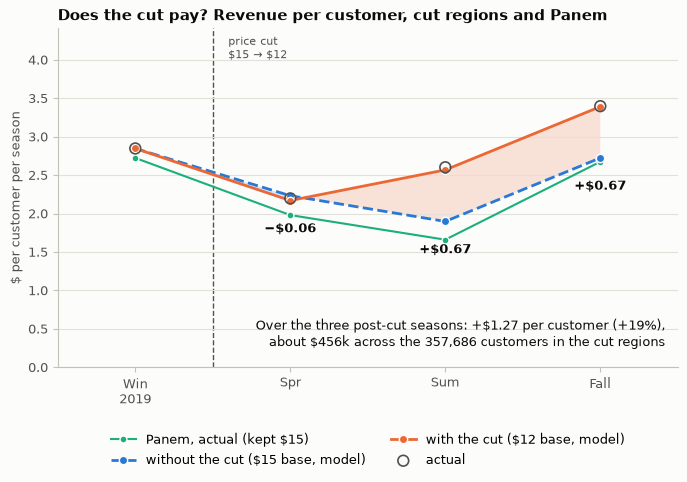

In [18]:
# Does the cut pay? Revenue per customer with the cut ($12 base) and without it ($15 base), from the same starting point.
# The shaded gap is the effect of the cut each season; actual revenue is shown as dots to show the model reproduces it.
# Panem (kept $15, never cut) is shown for reference: its own seasonal path, not a counterfactual for the cut regions.
x = np.array([CUT - 1, *POST])
start = cut_levels.loc[CUT - 1, 'revenue_pc']
cut_path, no_cut_path = np.r_[start, with_cut['revenue_pc']], np.r_[start, no_cut['revenue_pc']]
gain = with_cut['revenue_pc'] - no_cut['revenue_pc']
pct = with_cut['revenue_pc'].sum() / no_cut['revenue_pc'].sum() - 1

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.fill_between(x, cut_path, no_cut_path, where=cut_path >= no_cut_path, interpolate=True, color=ORANGE, alpha=0.18, lw=0)
ax.fill_between(x, cut_path, no_cut_path, where=cut_path < no_cut_path, interpolate=True, color=BLUE, alpha=0.18, lw=0)
panem_path = panem_levels.loc[x, 'revenue_pc'].to_numpy()
ax.plot(x, panem_path, color=u.THIRD_C, lw=1.5, marker='o', ms=5, mec=u.SURFACE, label='Panem, actual (kept \\$15)')
ax.plot(x, no_cut_path, color=BLUE, lw=2, ls='--', marker='o', mec=u.SURFACE, label='without the cut (\\$15 base, model)')
ax.plot(x, cut_path, color=ORANGE, lw=2, marker='o', mec=u.SURFACE, label='with the cut (\\$12 base, model)')
ax.scatter(x, cut_levels.loc[x, 'revenue_pc'], s=60, facecolor='none', edgecolor=u.INK2, linewidth=1.2, zorder=4,
           label='actual')
money = lambda v: f"{'+' if v >= 0 else '−'}\\${abs(v):.2f}"
for t, g in gain.items():
    low = min(with_cut.loc[t, 'revenue_pc'], no_cut.loc[t, 'revenue_pc'])
    ax.annotate(money(g), (t, low), xytext=(0, -16), textcoords='offset points', ha='center', va='top', fontsize=9,
                color=u.INK, weight='bold')
ax.text(0.98, 0.05, f'Over the three post-cut seasons: {money(gain.sum())} per customer ({100 * pct:+.0f}%),\n'
                    f'about \\${gain.sum() * n / 1e3:,.0f}k across the {n:,} customers in the cut regions',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9, color=u.INK)
u.mark_cut(ax)
u._period_axis(ax, x)
ax.set_ylim(0, max(cut_path.max(), no_cut_path.max(), panem_path.max()) * 1.3)
ax.set_ylabel('\\$ per customer per season')
ax.set_title('Does the cut pay? Revenue per customer, cut regions and Panem')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.show()

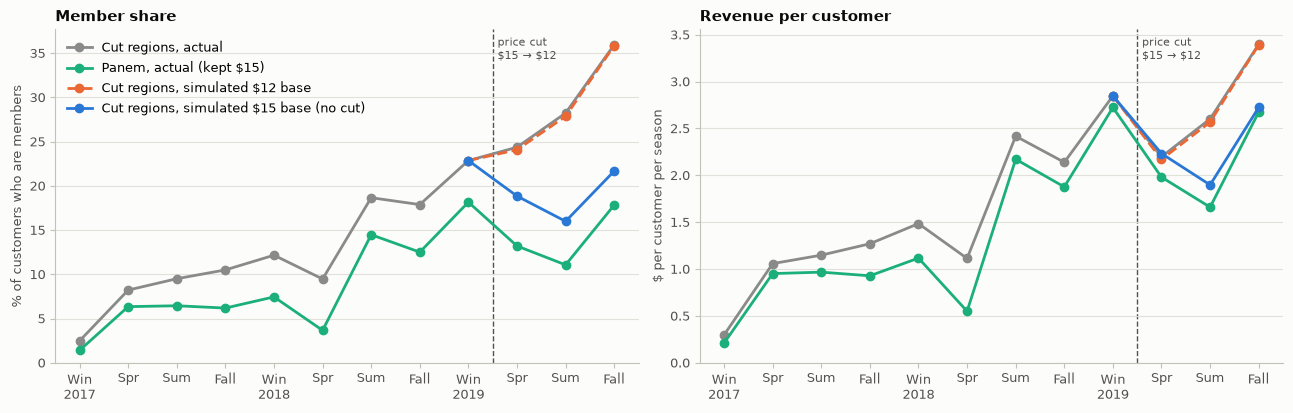

In [19]:
# Actual for the cut regions and Panem in every season; the two simulated paths branch off at winter 2019
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
anchor = cut_levels.loc[[CUT - 1]]
for ax, col, title, unit in zip(axes, ['member_pct', 'revenue_pc'], ['Member share', 'Revenue per customer'],
                                ['% of customers who are members', '$ per customer per season']):
    ax.plot(cut_levels.index, cut_levels[col], color=GREY, lw=2, marker='o', label='Cut regions, actual')
    ax.plot(panem_levels.index, panem_levels[col], color=u.THIRD_C, lw=2, marker='o', label='Panem, actual (kept $15)')
    for sim, color, ls, label in [(with_cut, ORANGE, '--', 'Cut regions, simulated $12 base'),
                                  (no_cut, BLUE, '-', 'Cut regions, simulated $15 base (no cut)')]:
        path = pd.concat([anchor[[col]], sim[[col]]])
        ax.plot(path.index, path[col], color=color, lw=2, marker='o', ls=ls, label=label)
    u.mark_cut(ax)
    u._period_axis(ax, cut_levels.index)
    ax.set_ylim(0, None)
    ax.set_ylabel(unit)
    ax.set_title(title, loc='left')
axes[0].legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

**Reading**

* **Simulated against actual.** At the \$12 base the simulation is within 0.35 pp on member share and \$0.03 on revenue per customer in every season. Both models were fit on data that includes these seasons, so this shows the roll-forward is consistent, not that it forecasts.
* **Membership.** The cut adds 5.3 pp in spring 2019, 11.9 pp in summer and 14.2 pp in fall. The effect builds because each season's extra members mostly stay.
* **Where it comes from.** With a \$15 base, about 16,400 members would have cancelled in spring 2019 against 7,600 at \$12, and about 2,100 prospects would have joined against 12,000.
* **Revenue.** Spring 2019 is slightly lower with the cut (−\$0.06 per customer): members pay \$3 less and the extra members have not built up yet. Summer and fall are about \$0.67 higher.
* **Against Part 1.** Membership and dollar revenue agree with the DiD. On percentage revenue the model's +0.165 is higher than the DiD's +0.015 but inside its interval; the DiD rests on one control region and cannot separate a gain of this size from zero.

**Caveats**

* This covers three seasons. It says nothing about whether the gain lasts.
* The comparison is model against model. Any error the two models share in both scenarios cancels; an error in how they respond to price does not.
* Revenue, not margin.